# Stiffness — a.k.a. "the thing that makes my simulation slow"

Stiffness is one of the main reasons why numerical simulations are slow.
It is also surprisingly hard to define: there is no single accepted mathematical definition, but several related mechanisms that make a PDAE system behave this way.

**TODO (hook plot):** two simulations of the same model with the same number of unknowns, one far slower than the other, differing only in the binding rate constants. *Which one is the big model?* — neither. Needs a setting that actually shows the effect, see the end of this notebook.

## What is it

A system is stiff when the time integrator is forced into **much smaller time steps than the result you look at would require**, because something in the system is much faster than what you actually care about.
Smaller steps mean more computations and therefore longer simulations.

The cleanest way to see this is a system small enough to fit on one slide.

### A system with two time scales

Two coupled processes, written as a linear system of ODEs:

$$
\frac{\mathrm{d}}{\mathrm{d}t}
\begin{pmatrix} y_1 \\ y_2 \end{pmatrix}
=
\begin{pmatrix} -500.5 & 499.5 \\ 499.5 & -500.5 \end{pmatrix}
\begin{pmatrix} y_1 \\ y_2 \end{pmatrix},
\qquad
\begin{pmatrix} y_1(0) \\ y_2(0) \end{pmatrix} = \begin{pmatrix} 1 \\ 0 \end{pmatrix}
$$

Nothing about those four numbers looks dramatic. The analytical solution shows what they mean:

$$
y(t) \;=\; \underbrace{\tfrac{1}{2}\, e^{-t} \begin{pmatrix} 1 \\ 1 \end{pmatrix}}_{\text{slow: seconds}}
\;+\; \underbrace{\tfrac{1}{2}\, e^{-1000\,t} \begin{pmatrix} 1 \\ -1 \end{pmatrix}}_{\text{fast: milliseconds}}
$$

One process decays over seconds, the other over milliseconds.
After roughly five milliseconds the fast one is gone, and what is left is a plain exponential decay.

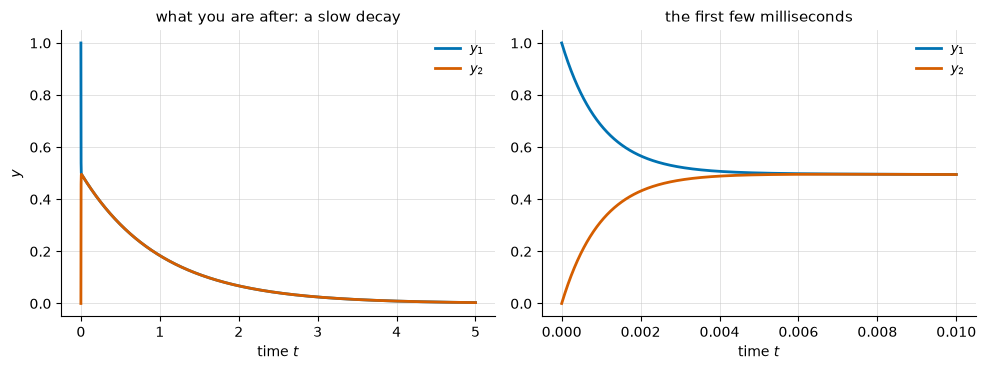

In [2]:
import numpy as np

import utility.stiffness_demos as demos

demos.plot_two_scale_solution(t_end=5.0, zoom_end=0.01);

### Integrating it with a large time step

The answer we care about lives on the slow scale, so $h = 0.1$ should be plenty — fifty steps for the whole curve.
Let us try the two simplest representatives of their kind:

- **explicit Euler**, $\;y_{n+1} = y_n + h\,A\,y_n\;$ — the new value is written down from the old one, nothing has to be solved.
- **implicit Euler**, $\;(I - h\,A)\,y_{n+1} = y_n\;$ — a system of equations has to be solved for every single step. CADET's model equations are nonlinear, so there it is a Newton solve.

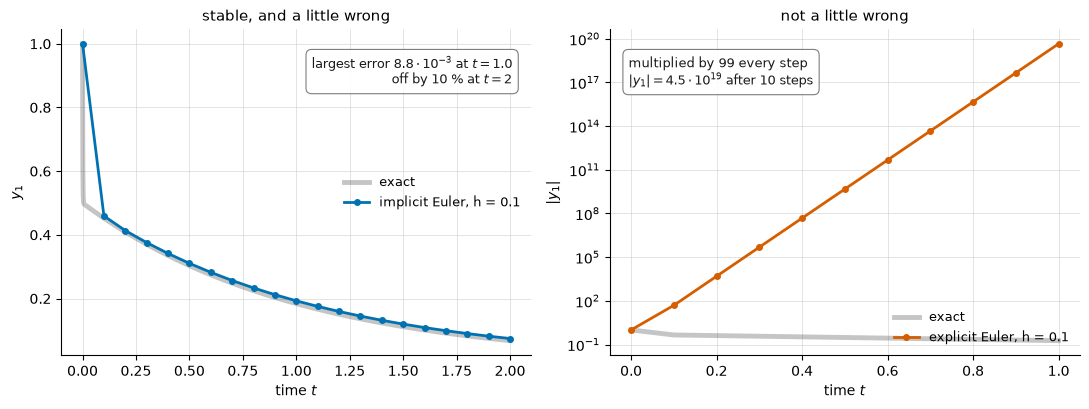

In [3]:
A = demos.two_scale_system(slow=-1.0, fast=-1000.0)
y0 = np.array([1.0, 0.0])

time_implicit, y_implicit = demos.implicit_euler(A, y0, h=0.1, t_end=2.0)

# Ten steps are enough to see where the explicit one is going.
time_explicit, y_explicit = demos.explicit_euler(A, y0, h=0.1, t_end=1.0)

demos.plot_accuracy_and_blowup(
    ("implicit Euler, h = 0.1", time_implicit, y_implicit),
    ("explicit Euler, h = 0.1", time_explicit, y_explicit),
    t_end=2.0,
);


### What is happening here?

The implicit solution is **not quite right**. It steps straight over the fast transient and then runs slightly above the exact curve. That is an *accuracy* problem: it gets a little smaller every time you shrink the step.

The explicit solution is not inaccurate. It is **destroyed** — note the logarithmic axis on the right. And it would not improve a little if we shrank the step a little: below a certain step size it simply works, above it the solution explodes. That is a *stability* problem, a threshold rather than a trend.

> **An implicit method chooses its step size for accuracy. An explicit method has its step size dictated by stability.**

And here is the part that matters for everything that follows: the stability limit is set by the **fastest** process in the system, whether or not you care about it. Our fast process is over after five milliseconds, and it still dictates the step size for the remaining five seconds.

<details>
<summary><b>Click to learn more about stability</b></summary>

The behaviour of a linear system is governed by the **eigenvalues** of its matrix, here

$$\lambda_{\text{slow}} = -1, \qquad \lambda_{\text{fast}} = -1000,$$

which are exactly the two decay rates in the analytical solution above. One step of a method multiplies each eigen-component by an amplification factor $R(z)$, where $z = h\lambda$ is the **scaled eigenvalue**:

$$R_{\text{explicit}}(z) = 1 + z, \qquad\qquad R_{\text{implicit}}(z) = \frac{1}{1-z}.$$

A component stays bounded if $|R(z)| \le 1$, and the set of all $z$ for which that holds is the method's **stability region**.

For explicit Euler, $|1 + z| \le 1$ is a disk of radius one around $-1$, so we need $-2 < h\lambda < 0$. With $\lambda = -1000$ that is $h < 0.002$, and our $h = 0.1$ is fifty times too large: the fast component gets multiplied by $1 - 100 = -99$ every step. Runge-Kutta 4 has a larger region, but it is still bounded — no explicit method escapes this.

For implicit Euler, $|1/(1-z)| \le 1$ holds for *every* $z$ in the left half plane. Every decaying process is stable at every step size. That is what you buy with the solve in every step.

<img src="data/img/stability_regions.png" width="860" alt="stability regions of explicit and implicit methods">

The ratio $|\lambda_{\text{fast}}| / |\lambda_{\text{slow}}| = 1000$ is sometimes called the **stiffness ratio**. It is a crude indicator, but it carries the right intuition: the further apart the time scales, the wider the gap between the step size your result needs and the step size your method is allowed.

</details>

### A smaller time step

Below $h = 0.002$ the explicit method is stable. Let us take $h = 0.001$ and run both again.

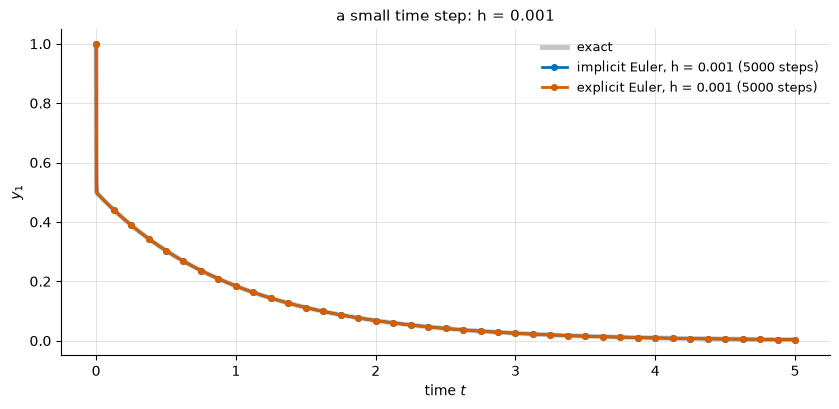

In [4]:
time_explicit, y_explicit = demos.explicit_euler(A, y0, h=0.001, t_end=5.0)
time_implicit, y_implicit = demos.implicit_euler(A, y0, h=0.001, t_end=5.0)

demos.plot_two_scale_runs(
    [(f"implicit Euler, h = 0.001 ({len(time_implicit) - 1} steps)",
      time_implicit, y_implicit),
     (f"explicit Euler, h = 0.001 ({len(time_explicit) - 1} steps)",
      time_explicit, y_explicit)],
    t_end=5.0, ylim=(-0.05, 1.05), title="a small time step: h = 0.001",
);

Both work now, both are accurate, and both needed **5000 steps** for a curve that the implicit method had already drawn in 50 — not well, but recognisably.

The difference is who had a choice:

- the explicit method had **none**. 5000 steps is the price of stability, and 4950 of them exist only because the system still *contains* a process that was over after five milliseconds.
- the implicit method has one. It took 5000 steps here because we asked it to. Asked for a coarser answer it takes 50, asked for a more accurate one it takes more — always for accuracy, never for stability.

**That gap is the stiffness**: the gap between the step size your answer needs and the step size the fastest process in the system allows.
So choosing an implicit method is not a way of making a problem un-stiff.
It removes the stability constraint.
The fast process is still in the system, and it still costs via having to solve a nonlinear system.

### What this means for CADET

CADET integrates implicitly because it solves a large family of models: transport, adsorption kinetics, reactions, particles, and combinations of them.
Those models are **usually stiff**, so implicit time integration is the robust and usually efficient choice.

So **in CADET, stiffness never breaks your simulation but bills you for it.**
The symptom is not a crash. The symptom is the clock.

## Where does it come from

So a simulation that requires a lot of compute is stiff?
Not necessarily. It might just be a large problem. It might just be a low error tolerance.
Identifying the source of a slow / long simulation allows reducing the computational effort for some.
In chromatography, there are seven recurring sources for stiffness:

| # | Cause | Mechanism | Who controls it |
|---|-------|-----------|-----------------|
| 1 | **Different time scales** | Adsorption or chemical reactions can be almost instantaneous, while pore diffusion and convection take much longer. The integrator keeps resolving the fast process long after it has settled into quasi-equilibrium. | model |
| 2 | **Different length scales** | Particle radius ≈ 45 µm against a bed length of ≈ 1.4 cm. Diffusion times scale with $L^2/D$, so the particle equilibrates orders of magnitude faster than the column. Things simply happen faster in small geometries. | model |
| 3 | **Steep gradients** | Self-sharpening Langmuir fronts, step injections, breakthrough. Here it is not the equations but the *current solution* that causes the trouble. | model + feed |
| 4 | **The grid itself** | The discretization turns spatial derivatives into eigenvalues that grow as you refine: roughly $u/\Delta x$ for convection and $D/\Delta x^2$ for dispersion. An implicit integrator absorbs most of that, so you usually pay in cost *per* step rather than in *more* steps — but you do pay, and this is the one cause you set yourself. | **user** |
| 5 | **Flow and geometry** | The interstitial velocity sets the convective time scale, and it is higher at smaller cross sections. Radial-flow and frustum columns have a velocity that varies along the bed, so the tightest limit is set locally. | model |
| 6 | **Events** | Every section transition and valve switch is a discontinuity. The integrator restarts at low order with a tiny step size and has to climb back up, plus a consistent initialization each time. Gradient staircases and SMB switching pay that price over and over. | user |
| 7 | **Scaling** | Salt at $10^2$–$10^3$ mol m$^{-3}$ next to proteins at $10^{-3}$. A single global `ABSTOL` either over-resolves the protein or ignores it, and a badly scaled Jacobian makes the Newton solve struggle. | user |

Two things we should be honest about:

- **#3 and #7 are not stiffness in the strict mathematical sense.** They are accuracy and nonlinear-convergence problems. But the symptoms — small time steps, many Newton iterations, long runtimes — are identical, and so is your experience of them.
- **Dispersion cuts both ways.** It raises the diffusive eigenvalues, which is stiffer, but it also smooths out steep fronts, which helps with #3. Which effect wins is a question for the experiment, not for the lecture.

### What is *not* stiffness, but also makes it slow

Worth naming, so that nobody misdiagnoses: the sheer size of the model, the number of components and particle types, the number of output time points and writing out the full bulk/particle solution, parameter sensitivities, running single-threaded, and an algorithmically differentiated instead of an analytic Jacobian.

## How do I see it?

A feeling that "it is slow" is not a diagnosis. What we can measure:

1. **Wall-clock time** — the blunt instrument, and the one every user already has.
2. **Number of internal time steps, and the step size over simulated time.** This is the telling picture: mark the section boundaries and you see both the restarts and the integrator crawling through a steep front.
3. **Newton convergence failures and error-test failures** from the CADET log — these separate "stiff" from "nonlinearly hard".
4. **Rule of thumb:** internal steps per second of simulated time. If that is far above what the shape of your chromatogram requires, something fast is being resolved that you do not care about.

**TODO:** check what CADET actually returns here. With `USER_SOLUTION_TIMES` set, the returned times are the ones you requested, not the integrator's own steps. Then collect it in `utility/stiffness_metrics.py` so that every notebook of this chapter measures the same way.

## What can I do about it

| Cause | First thing to try | What it costs you |
|-------|--------------------|-------------------|
| fast binding kinetics (#1) | rapid equilibrium, `IS_KINETIC = 0` | you get a DAE instead of an ODE, so consistent initialization matters; only valid if the kinetics really are fast |
| particle resolution (#2) | LRMP or LRM instead of GRM | model fidelity — there is no pore gradient any more |
| steep fronts (#3) | FV with WENO, or DG with oscillation suppression; dispersion if you can justify it physically | accuracy, or model fidelity if you add dispersion you cannot justify |
| the grid (#4) | find the coarsest grid that still meets your accuracy target — **do this before anything else** | nothing. This is free money, and most users leave it on the table |
| tolerances | match `ABSTOL`/`RELTOL` to the accuracy you actually need, and to the magnitudes of your components | accuracy, honestly accounted for |
| many sections (#6) | merge sections, or use a smooth polynomial gradient instead of a staircase | a slightly different feed profile |
| scaling (#7) | component-appropriate tolerances and sane units | nothing |

<details>
<summary><b>Click to learn more: specialized time integration, and why it is not in CADET</b></summary>

Specialized methods can exploit the separation of time scales. **IMEX** methods treat the stiff processes implicitly and the rest explicitly; **multirate** methods advance different processes with different step sizes.
Both need additional knowledge of the model structure and careful handling of the coupling between processes, which is hard to provide in a general-purpose code — although CADET's modular structure would be a reasonable starting point for future work in that direction.

IMEX methods have been demonstrated for chromatography models in the literature. They have not established a general performance advantage over conventional implicit integrators such as adaptive BDF, which remains the standard choice in established chromatography simulators, and no open-source implementation is available.

**TODO:** proper citations.
- https://www.sciencedirect.com/science/article/pii/S0168927417301812
- https://www.sciencedirect.com/science/article/pii/S0098135417304362
- https://www.sciencedirect.com/science/chapter/bookseries/abs/pii/B9780444642417501373

</details>

### Key takeaway

> **A slow simulation is not necessarily a big simulation.** A small model with one very fast process, one very steep front, or one needlessly fine grid can cost more than a large, well-behaved one.

## What comes next

One notebook per source of stiffness. Each sets up a chromatography problem that exercises exactly that mechanism, follows the same path — **setting → the one knob → measure → mitigate → honest limitation** — and ends with what you cannot fix.

| Notebook | Setting | The knob |
|----------|---------|----------|
| `Stiffness 1 – Time scales` | LWE / SMA, GRM | binding rate constants (equilibrium unchanged), then `IS_KINETIC` |
| `Stiffness 2 – Steep fronts` | 2-component Langmuir, LRM | `COL_DISPERSION`, sharpness of the feed profile |
| `Stiffness 3 – Length scales` | LWE, GRM vs. LRMP vs. LRM | `PAR_RADIUS`, `PORE_DIFFUSION`, transport model |
| `Stiffness 4 – The grid` | LWE, DG and FV | number of cells, polynomial degree |
| `Stiffness 5 – Events and scaling` | LWE with its three sections | number and length of sections, `ABSTOL` vs. component magnitudes |

**Open question for notebook 1:** we still need a configuration in which speeding up the binding kinetics measurably increases the integrator work, and in which switching to rapid equilibrium brings it back down. The SMA load-wash-elute case is not it: at its rate constants the binding is already at equilibrium, and kinetic and rapid-equilibrium runs take the same 1041 time steps. Finding a setting that shows the effect is the first task of that notebook.

Not every simulation can be made fast. Where that is the case, we say so.